# **Predviđanje uspeha studenata**

Rešava se problem ranog prepoznavanja da li će student da diplomira ili odustane. U pitanju je klasifikacio ni problem za 3 klase (odustao, diplomnirao i još studira).

## Priprema podataka

### Uvođenje biblioteka

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer

In [2]:
import importlib.util
import sys

def package_install(package_name):
    if importlib.util.find_spec(package_name) is None:
        print(f'{package_name} nije instaliran. Instaliram...')
        !{sys.executable} -m pip install {package_name}
    else:
        print(f'{package_name} je već instaliran.')

In [3]:
package_install('ucimlrepo')
package_install('imbalanced-learn')

ucimlrepo je već instaliran.
imbalanced-learn nije instaliran. Instaliram...


In [4]:
from ucimlrepo import fetch_ucirepo
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.pipeline import Pipeline

# fetch dataset
predict_students_dropout_and_academic_success = fetch_ucirepo(id=697)

# data (as pandas dataframes)
X = predict_students_dropout_and_academic_success.data.features
y = predict_students_dropout_and_academic_success.data.targets


### EDA

In [5]:
X = X.drop_duplicates()
y=y.loc[X.index]


In [6]:
y.head()

,Target
0,Dropout
1,Graduate
2,Dropout
3,Graduate
4,Graduate


In [7]:
opis = ''
oblik = f'Baza ima {X.shape[0]} uzoraka i {X.shape[1]} obeležja.'
print(oblik)
opis += oblik

Baza ima 4424 uzoraka i 36 obeležja.


Baza ima 4424 uzoraka i 36 obeležja.

In [8]:
X.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79


In [9]:
obelezja = f'Obeležja u tabeli su {', '.join(X.columns.values)}.'
print(obelezja)
opis += obelezja

Obeležja u tabeli su Marital Status, Application mode, Application order, Course, Daytime/evening attendance, Previous qualification, Previous qualification (grade), Nacionality, Mother's qualification, Father's qualification, Mother's occupation, Father's occupation, Admission grade, Displaced, Educational special needs, Debtor, Tuition fees up to date, Gender, Scholarship holder, Age at enrollment, International, Curricular units 1st sem (credited), Curricular units 1st sem (enrolled), Curricular units 1st sem (evaluations), Curricular units 1st sem (approved), Curricular units 1st sem (grade), Curricular units 1st sem (without evaluations), Curricular units 2nd sem (credited), Curricular units 2nd sem (enrolled), Curricular units 2nd sem (evaluations), Curricular units 2nd sem (approved), Curricular units 2nd sem (grade), Curricular units 2nd sem (without evaluations), Unemployment rate, Inflation rate, GDP.


Delimo podatke na kategoričke i numeričke.

In [10]:
numerička = X.columns[[2,6,12,19] + list(range(21, 36))]
print(numerička)
print(len(numerička))

Index(['Application order', 'Previous qualification (grade)',
       'Admission grade', 'Age at enrollment',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)', 'Unemployment rate',
       'Inflation rate', 'GDP'],
      dtype='object')
19


In [11]:
kategorička = X.columns.drop(numerička)
print(kategorička)
print(len(kategorička))

Index(['Marital Status', 'Application mode', 'Course',
       'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Displaced',
       'Educational special needs', 'Debtor', 'Tuition fees up to date',
       'Gender', 'Scholarship holder', 'International'],
      dtype='object')
17


In [12]:
X_kategorička = X[kategorička].copy()
X_numerička = X[numerička].copy()

In [13]:
categorical_value_names = {
    "Marital Status": {
        1: "Single",
        2: "Married",
        3: "Widowed",
        4: "Divorced",
        5: "Facto Union",
        6: "Legally Separated",
    },
    "Application mode": {
        1: "1st Phase - General",
        2: "Ord. 612/93",
        5: "1st Phase - Spec. (Azores)",
        7: "Holders of HE Degree",
        10: "Ord. 854-B/99",
        15: "Int. Student (BSc)",
        16: "1st Phase - Spec. (Madeira)",
        17: "2nd Phase - General",
        18: "3rd Phase - General",
        26: "Ord. 533-A/99 (B2)",
        27: "Ord. 533-A/99 (B3)",
        39: "Over 23 Years Old",
        42: "Transfer",
        43: "Course Change",
        44: "Tech. Spec. Diploma",
        51: "Inst./Course Change",
        53: "Short Cycle Diploma",
        57: "Int. Change Inst./Course",
    },
    "Course": {
        33: "Biofuel Production Tech.",
        171: "Animation & Multimedia Design",
        8014: "Social Service (Evening)",
        9003: "Agronomy",
        9070: "Communication Design",
        9085: "Veterinary Nursing",
        9119: "Informatics Engineering",
        9130: "Equinculture",
        9147: "Management",
        9238: "Social Service (Day)",
        9254: "Tourism",
        9500: "Nursing",
        9556: "Oral Hygiene",
        9670: "Advertising & Marketing",
        9773: "Journalism & Comm.",
        9853: "Basic Education",
        9991: "Management (Evening)",
    },
    "Daytime/evening attendance": {
        0: "Evening",
        1: "Daytime",
    },
    "Previous qualification": {
        1: "Secondary Education",
        2: "Higher Ed. - Bachelor",
        3: "Higher Ed. - Degree",
        4: "Higher Ed. - Master",
        5: "Higher Ed. - Doctorate",
        6: "Incomplete Higher Ed.",
        9: "12th Year (Incomplete)",
        10: "11th Year (Incomplete)",
        12: "11th Year (Completed)",
        14: "10th Year (Completed)",
        15: "10th Year (Incomplete)",
        19: "Basic Ed. 3rd Cycle",
        38: "Basic Ed. 2nd Cycle",
        39: "Tech. Spec. Course",
        40: "Higher Ed. - 1st Cycle",
        42: "Prof. Higher Tech. Course",
        43: "Higher Ed. - 2nd Cycle",
    },
    "Nacionality": {
        1: "Portuguese", 2: "German", 6: "Spanish", 11: "Italian",
        13: "Dutch", 14: "English", 17: "Lithuanian", 21: "Angolan",
        22: "Cape Verdean", 24: "Guinean", 25: "Mozambican", 26: "Santomean",
        32: "Turkish", 41: "Brazilian", 62: "Romanian", 100: "Moldovan",
        101: "Mexican", 103: "Ukrainian", 105: "Russian", 108: "Cuban", 109: "Colombian",
    },
    "Mother's qualification" : {
        1: "Secondary Education",
        2: "Higher Ed. - Bachelor",
        3: "Higher Ed. - Degree",
        4: "Higher Ed. - Master",
        5: "Higher Ed. - Doctorate",
        6: "Incomplete Higher Ed.",
        9: "12th Year (Incomp.)",
        10: "11th Year (Incomp.)",
        11: "7th Year (Old System)",
        12: "11th Year",
        14: "10th Year",
        18: "General Commerce",
        19: "Basic Ed. 3rd Cycle",
        22: "Tech.-Professional",
        26: "7th Year",
        27: "HS 2nd Cycle",
        29: "9th Year (Incomp.)",
        30: "8th Year",
        34: "Unknown",
        35: "Illiterate",
        36: "Basic Literacy",
        37: "Basic Ed. 1st Cycle",
        38: "Basic Ed. 2nd Cycle",
        39: "Tech. Spec. Course",
        40: "Higher Ed. 1st Cycle",
        41: "Spec. Higher Studies",
        42: "Prof. Higher Tech.",
        43: "Higher Ed. 2nd Cycle",
        44: "Higher Ed. 3rd Cycle",
    },
    "Father's qualification": {
        1: "Secondary Education",
        2: "Higher Ed. - Bachelor",
        3: "Higher Ed. - Degree",
        4: "Higher Ed. - Master",
        5: "Higher Ed. - Doctorate",
        6: "Incomplete Higher Ed.",
        9: "12th Year (Incomp.)",
        10: "11th Year (Incomp.)",
        11: "7th Year (Old System)",
        12: "11th Year",
        14: "10th Year",
        18: "General Commerce",
        19: "Basic Ed. 3rd Cycle",
        22: "Tech.-Professional",
        26: "7th Year",
        27: "HS 2nd Cycle",
        29: "9th Year (Incomp.)",
        30: "8th Year",
        34: "Unknown",
        35: "Illiterate",
        36: "Basic Literacy",
        37: "Basic Ed. 1st Cycle",
        38: "Basic Ed. 2nd Cycle",
        39: "Tech. Spec. Course",
        40: "Higher Ed. 1st Cycle",
        41: "Spec. Higher Studies",
        42: "Prof. Higher Tech.",
        43: "Higher Ed. 2nd Cycle",
        44: "Higher Ed. 3rd Cycle",
    },
    "Mother's occupation": {
        0: "Student",
        1: "Exec. Managers / Directors",
        2: "Intellectual / Scientific",
        3: "Intermediate Tech. Prof.",
        4: "Administrative Staff",
        5: "Services & Sales",
        6: "Agri. / Fishery Skilled",
        7: "Industry / Craft Skilled",
        8: "Machine / Assembly Ops.",
        9: "Unskilled Workers",
        10: "Armed Forces",
        90: "Other",
        99: "N/A",
        122: "Health Professionals",
        123: "Teachers",
        125: "ICT Specialists",
        131: "Sci. & Eng. Technicians",
        132: "Health Technicians",
        134: "Legal / Social Technicians",
        141: "Office / Data Operators",
        143: "Financial / Registry Ops.",
        144: "Admin. Support Staff",
        151: "Personal Service",
        152: "Sales Personnel",
        153: "Personal Care Workers",
        171: "Construction Workers",
        173: "Printing / Precision Crafts",
        175: "Food / Wood / Textile Ind.",
        191: "Cleaning Personnel",
        192: "Unskilled Agri. / Forestry",
        193: "Unskilled Mfg. / Transport",
        194: "Food Prep. Assistants",
    },
    "Father's occupation": {
        0: "Student",
        1: "Exec. Managers / Directors",
        2: "Intellectual / Scientific",
        3: "Intermediate Tech. Prof.",
        4: "Administrative Staff",
        5: "Services & Sales",
        6: "Agri. / Fishery Skilled",
        7: "Industry / Craft Skilled",
        8: "Machine / Assembly Ops.",
        9: "Unskilled Workers",
        10: "Armed Forces",
        90: "Other",
        99: "N/A",
        122: "Health Professionals",
        123: "Teachers",
        125: "ICT Specialists",
        131: "Sci. & Eng. Technicians",
        132: "Health Technicians",
        134: "Legal / Social Technicians",
        141: "Office / Data Operators",
        143: "Financial / Registry Ops.",
        144: "Admin. Support Staff",
        151: "Personal Service",
        152: "Sales Personnel",
        153: "Personal Care Workers",
        171: "Construction Workers",
        173: "Printing / Precision Crafts",
        175: "Food / Wood / Textile Ind.",
        191: "Cleaning Personnel",
        192: "Unskilled Agri. / Forestry",
        193: "Unskilled Mfg. / Transport",
        194: "Food Prep. Assistants",
    },
    "Displaced": {0: "No", 1: "Yes"},
    "Educational special needs": {0: "No", 1: "Yes"},
    "Debtor": {0: "No", 1: "Yes"},
    "Tuition fees up to date": {0: "No", 1: "Yes"},
    "Gender": {0: "Female", 1: "Male"},
    "Scholarship holder": {0: "No", 1: "Yes"},
    "International": {0: "No", 1: "Yes"},
}

def label_categorical_values(df, mappings):
    result = df.copy()
    for column, mapping in mappings.items():
        if column in result.columns:
            result[column] = result[column].replace(mapping)
    return result

In [14]:
dict_kateg = pd.Series({k:X_kategorička[k].nunique() for k in X_kategorička.columns})
print(dict_kateg)


Marital Status                 6
Application mode              18
Course                        17
Daytime/evening attendance     2
Previous qualification        17
Nacionality                   21
Mother's qualification        29
Father's qualification        34
Mother's occupation           32
Father's occupation           46
Displaced                      2
Educational special needs      2
Debtor                         2
Tuition fees up to date        2
Gender                         2
Scholarship holder             2
International                  2
dtype: int64


Ima 19 numeričkih i 17 kategoričkih obeležja.

In [15]:
print(f'Obeležja sa najmanje kategorija ({dict_kateg.min()}): { ', '.join([k[0] for k in dict_kateg.items() if k[1]==dict_kateg.min()]) }')

Obeležja sa najmanje kategorija (2): Daytime/evening attendance, Displaced, Educational special needs, Debtor, Tuition fees up to date, Gender, Scholarship holder, International


In [16]:
print(f'Obeležja sa najviše kategorija ({dict_kateg.max()}): { ', '.join([k[0] for k in dict_kateg.items() if k[1]==dict_kateg.max()]) }')

Obeležja sa najviše kategorija (46): Father's occupation


Target  
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target  
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64
100.0


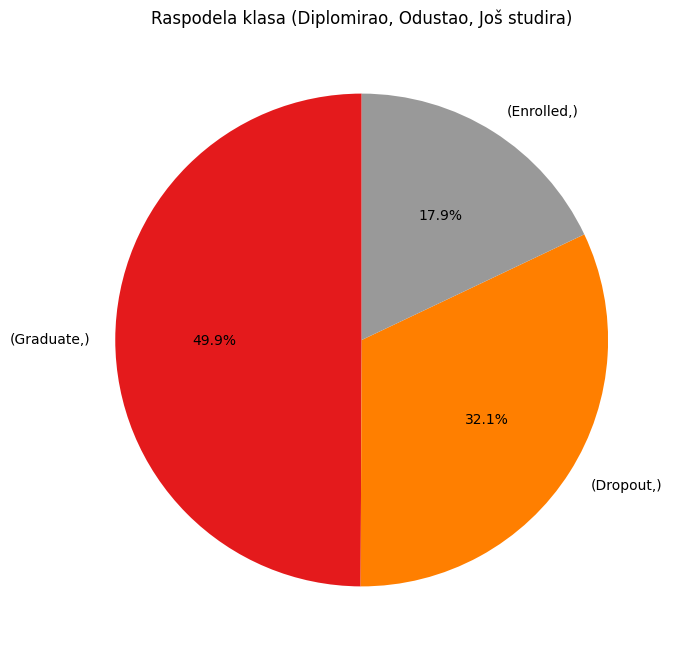

In [17]:
print(y.value_counts())
print(y.value_counts(normalize=True)*100)
print(y.value_counts(normalize=True).sum()*100)

plt.figure(figsize=(8, 8))
y.value_counts().plot.pie(autopct='%1.1f%%', startangle=90, cmap='Set1')
plt.title('Raspodela klasa (Diplomirao, Odustao, Još studira)')
plt.ylabel('') # Uklanja 'Target' labelu sa y-ose
plt.show()

Nema nedostajućih vrednosti.

In [18]:
missing_values_count = X.isnull().sum()
print('Broj nedostajućih vrednosti po obeležjima:')
print(missing_values_count)

Broj nedostajućih vrednosti po obeležjima:
Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder   

Kada prikažemo numerička obeležja grafički možemo videti da većina obelečja ima "rep" sa ddedsne strane što ukazuje na to da

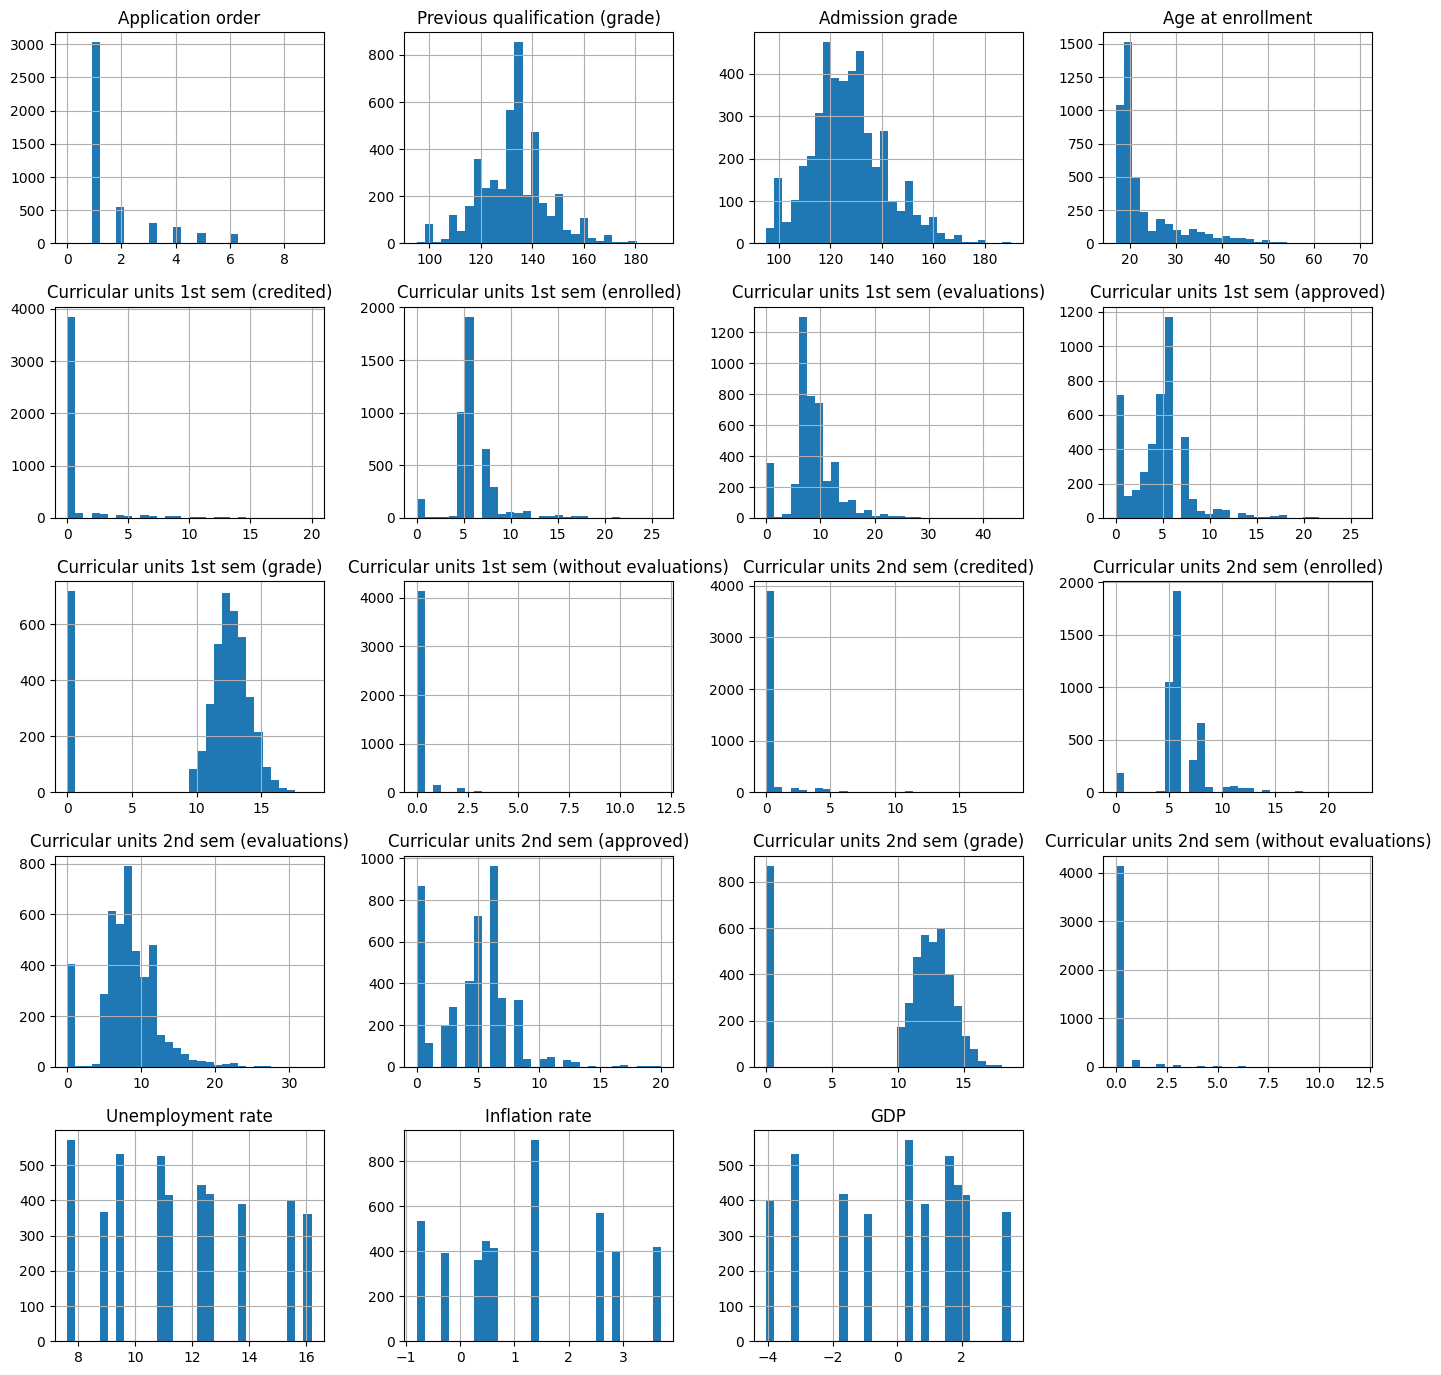

Index(['Application order', 'Previous qualification (grade)',
       'Admission grade', 'Age at enrollment',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)', 'Unemployment rate',
       'Inflation rate', 'GDP'],
      dtype='object')


In [19]:
X_numerička.hist(figsize=(17, 17), bins=30)
plt.autoscale()
plt.show()
print(numerička)

Nema obeležja za izbacivanje i nema nedostajućih vrednosti.

In [20]:
X_numerička.describe([0, 0.05, 0.95,0.98, 0.99])

,Application order,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.727848,132.613314,126.978119,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,1.313793,13.188332,14.482001,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,0.000000,95.000000,95.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
0%,0.000000,95.000000,95.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
5%,1.000000,110.000000,103.415000,18.000000,0.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
50%,1.000000,133.100000,126.100000,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
95%,5.000000,157.000000,153.500000,41.000000,6.000000,11.000000,15.000000,9.000000,14.857143,1.000000,4.000000,10.000000,15.000000,8.000000,14.980262,1.000000,16.200000,3.700000,3.510000
98%,6.000000,162.000000,160.000000,47.000000,10.000000,14.000000,19.000000,12.000000,15.571429,2.000000,8.000000,12.000000,17.000000,11.000000,15.635775,3.000000,16.200000,3.700000,3.510000
99%,6.000000,170.000000,166.831000,50.000000,13.000000,17.000000,21.000000,15.000000,16.000000,3.000000,11.000000,13.770000,19.000000,12.000000,16.000000,4.000000,16.200000,3.700000,3.510000


In [21]:
long_tail = ['Age at enrollment', 'Application order']
X[long_tail] = X[long_tail].clip(upper=X[long_tail].quantile(0.90), axis=1)
long_tail_s = ['Curricular units 2nd sem (credited)']
X[long_tail_s] = X[long_tail_s].clip(upper=X[long_tail_s].quantile(0.95), axis=1)
long_tail_xs = ['Curricular units 2nd sem (without evaluations)']
X[long_tail_xs] = X[long_tail_xs].clip(upper=X[long_tail_xs].quantile(0.99), axis=1)

tail = ['Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)']
X[tail] = X[tail].clip(upper=X[tail].quantile(0.97), axis=1)
cols = list(X_numerička.columns[4:8])+ list(X_numerička.columns[9:13]) + list(X_numerička.columns[14:16])


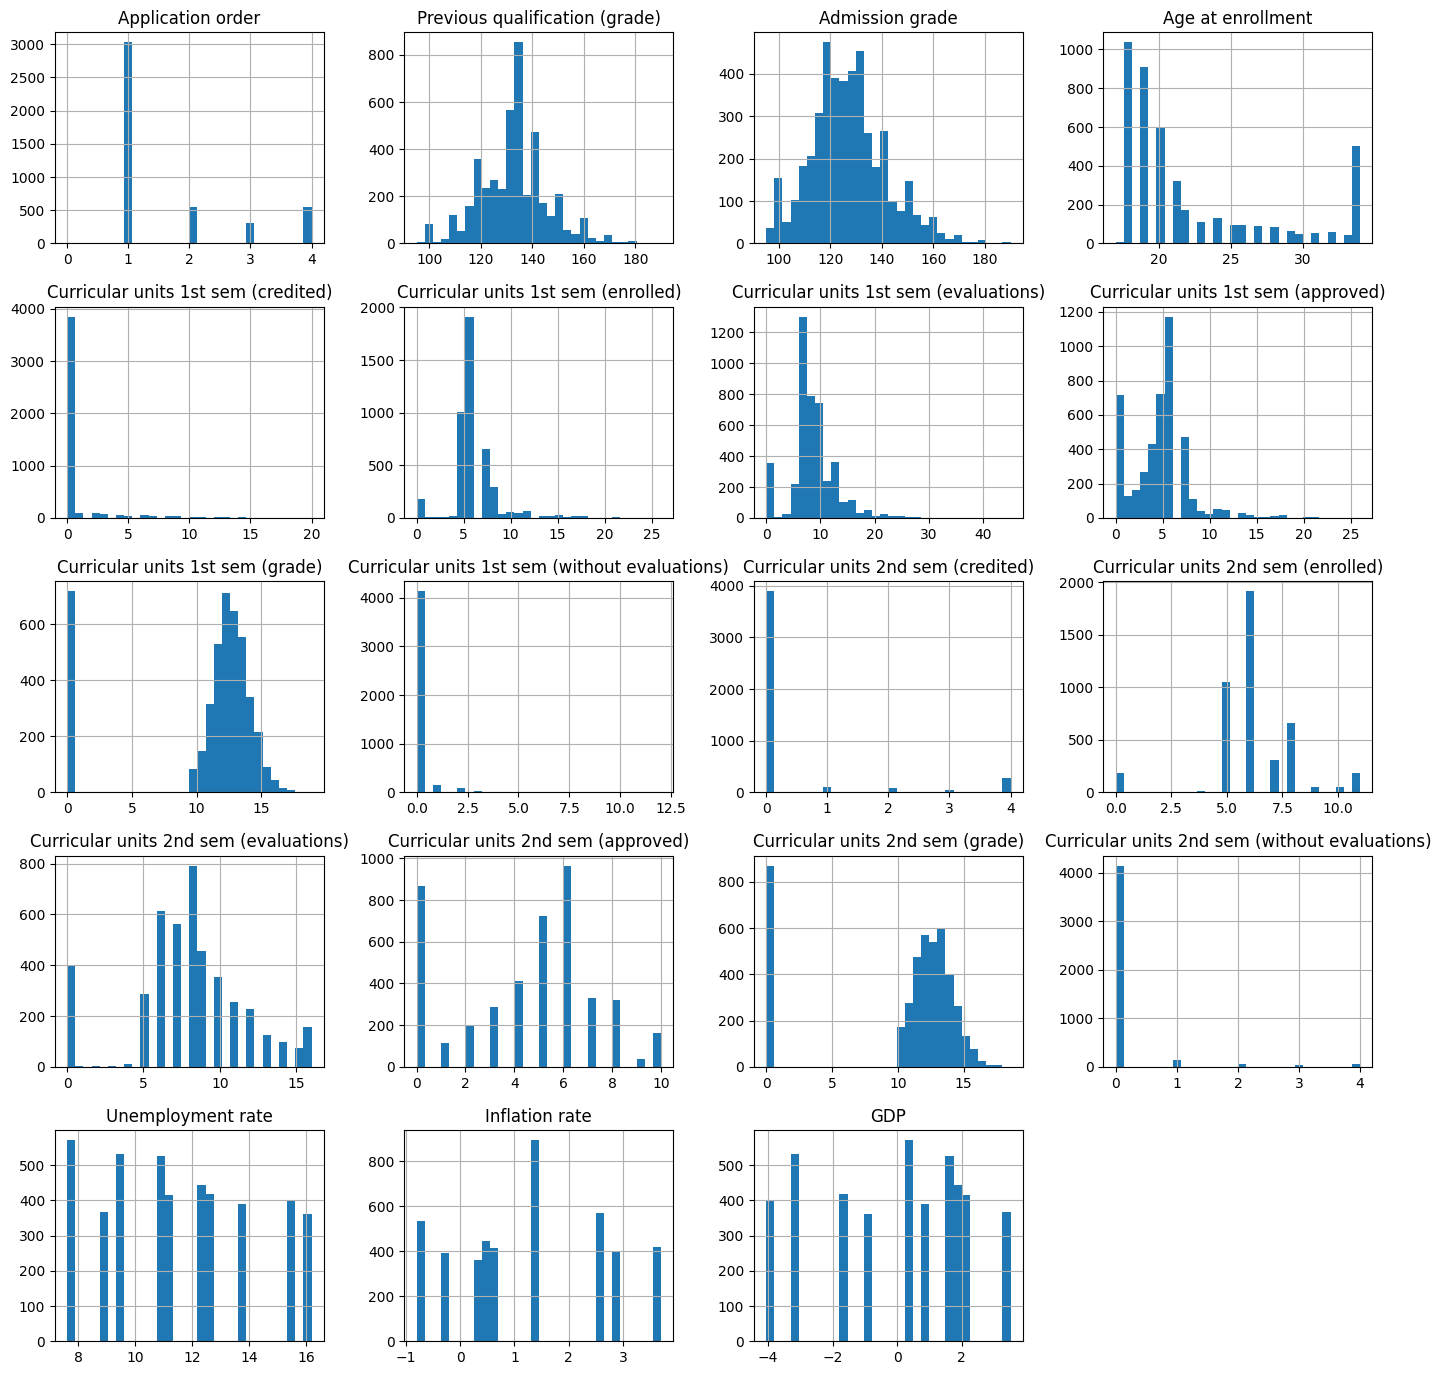

In [22]:
X[numerička].hist(figsize=(17, 17), bins=30)
plt.autoscale()
plt.show()

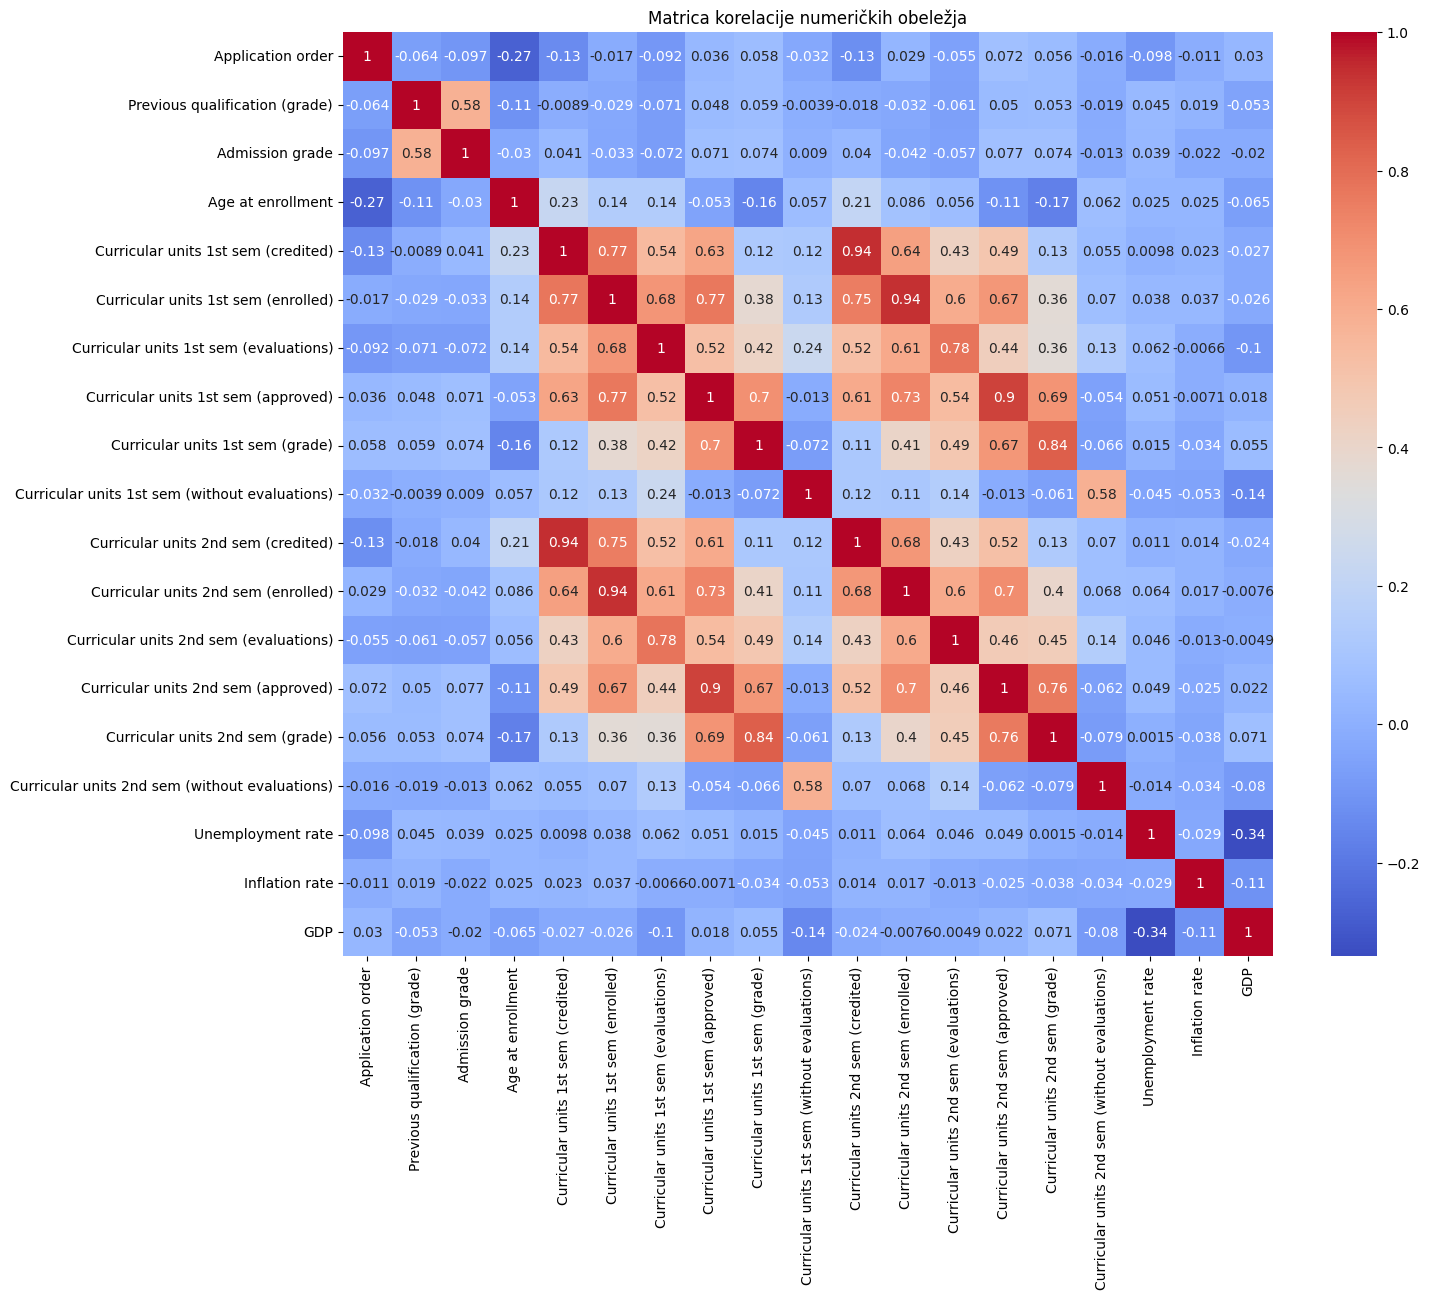

In [23]:
plt.figure(figsize=(15, 12))
sns.heatmap(X_numerička.corr(), annot=True, cmap='coolwarm')
plt.title('Matrica korelacije numeričkih obeležja')
plt.show()

In [24]:
columns_to_drop = [
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

X = X.drop(columns=columns_to_drop, errors='ignore')

numerička = numerička.drop(columns_to_drop)

In [25]:
full_df = pd.concat([X, y], axis=1)
print(f"Broj dupliranih redova: {full_df.duplicated().sum()}")

print("\nTipovi podataka u X:")
print(X.dtypes.value_counts())

print("\nBalans klasa (procentualni udeo):")
balans = y['Target'].value_counts(normalize=True) * 100
print(balans.map('{:f}%'.format))

temp_df = pd.concat([X, y], axis=1)
# Pretvaramo Target u brojeve: Graduate=0, Dropout=1, Enrolled=2 (ili slično)
temp_df['Target_encoded'] = temp_df['Target'].astype('category').cat.codes

print("\nTop 5 obeležja sa najjačim uticajem na ishod:")
correlations = temp_df.corr(numeric_only=True)['Target_encoded'].abs().sort_values(ascending=False)

print(correlations.iloc[1:6])

Broj dupliranih redova: 0

Tipovi podataka u X:
int64      24
float64     3
Name: count, dtype: int64

Balans klasa (procentualni udeo):
Target
Graduate    49.932188%
Dropout     32.120253%
Enrolled    17.947559%
Name: proportion, dtype: object

Top 5 obeležja sa najjačim uticajem na ishod:
Curricular units 2nd sem (approved)    0.651386
Curricular units 2nd sem (grade)       0.566827
Tuition fees up to date                0.409827
Scholarship holder                     0.297595
Age at enrollment                      0.283631
Name: Target_encoded, dtype: float64


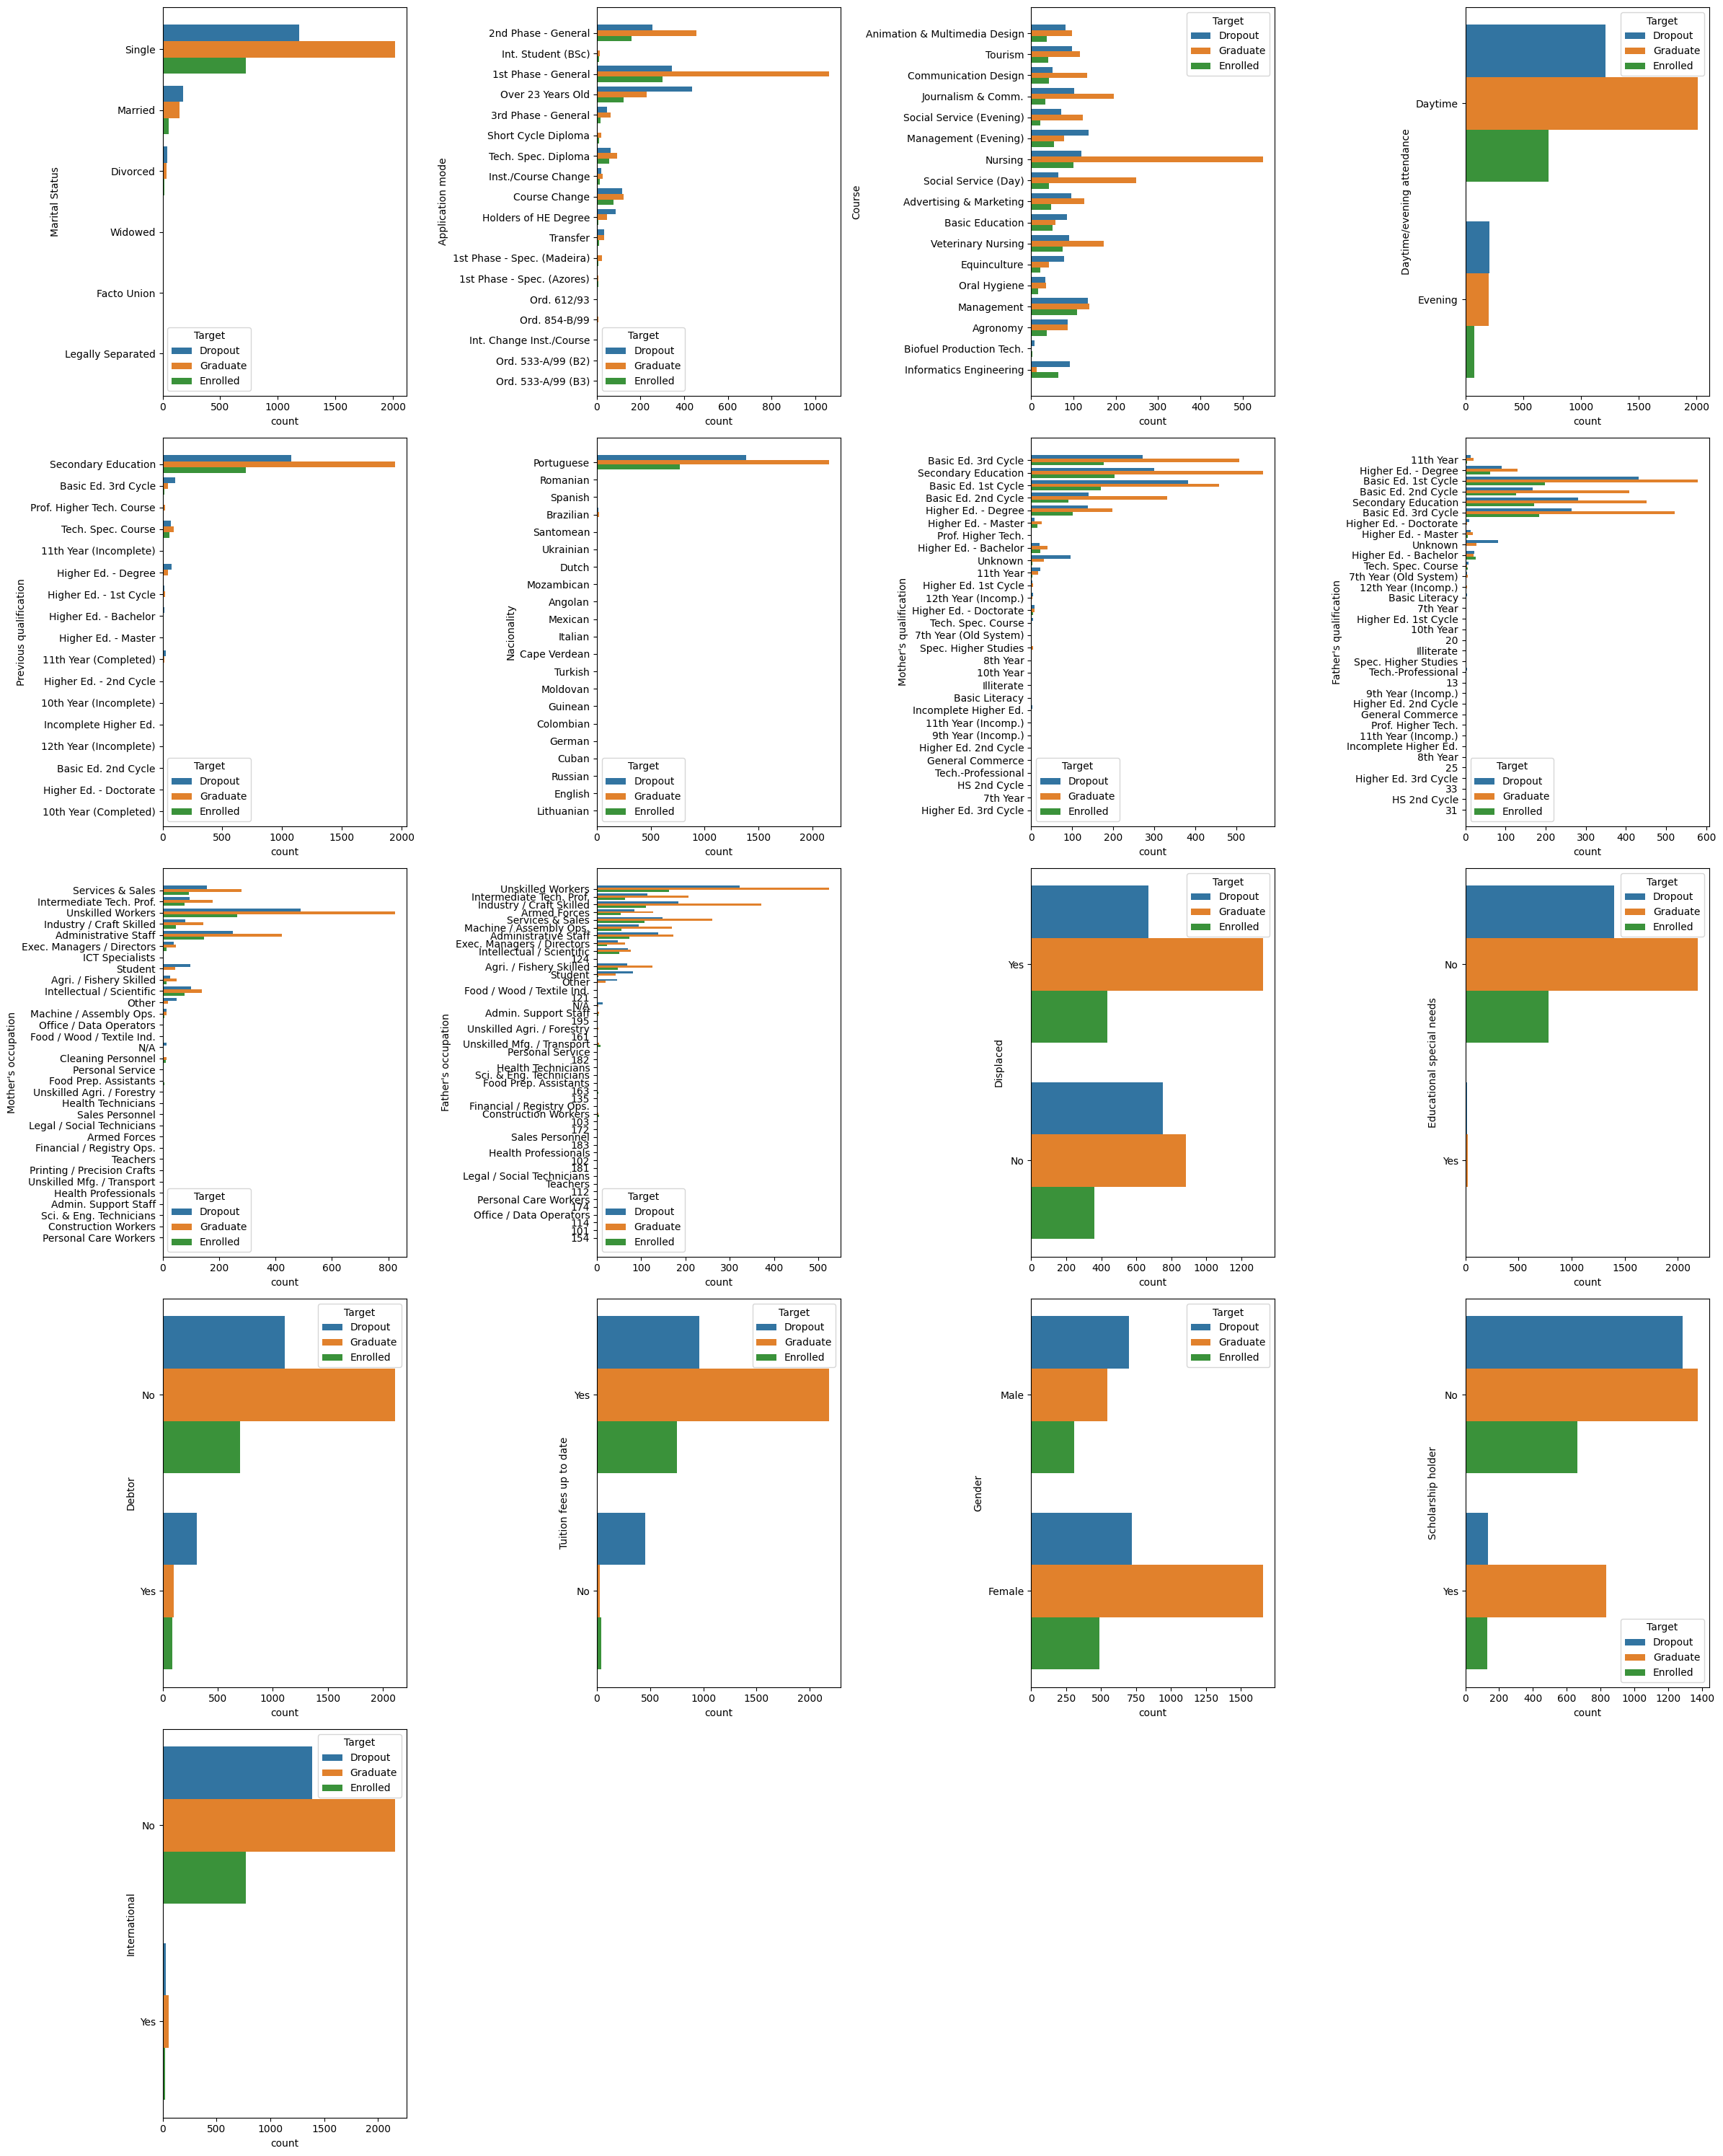

In [26]:
def plot_kategoricka():
    m = 4 if int(len(kategorička)**1/2) > 4 else int(len(kategorička)**1/2)
    n = math.ceil(len(numerička)/2)
    plt.figure(figsize=(m * 6, n * 6))
    for k in kategorička:
        plt.subplot(n, m, list(kategorička).index(k)+1)
        sns.countplot(y=X[k], hue=y['Target'])
        #plt.tick_params(axis='x', rotation=90)
        plt.tight_layout()
        plt.autoscale()
    plt.show()

X = label_categorical_values(X, categorical_value_names)
plot_kategoricka()

In [27]:
def other_categories(df, columns, percentile, min_rare_count=3, other_label='other'):
    if not 0 < percentile < 1:
        raise ValueError("percentile must be in decimal form, between 0 and 1, for example 0.05")
    if min_rare_count < 1:
        raise ValueError("min_rare_count must be >= 1")

    result = df.copy()
    rare_values_by_column = {}

    for column in columns:
        value_frequencies = result[column].value_counts(normalize=True, dropna=True)
        rare_values = value_frequencies[value_frequencies < percentile].index

        # Group only if there are enough rare categories in this column.
        if len(rare_values) >= min_rare_count:
            rare_values_by_column[column] = list(rare_values)
            result[column] = result[column].where(~result[column].isin(rare_values), other_label)
        else:
            rare_values_by_column[column] = []

    return result, rare_values_by_column


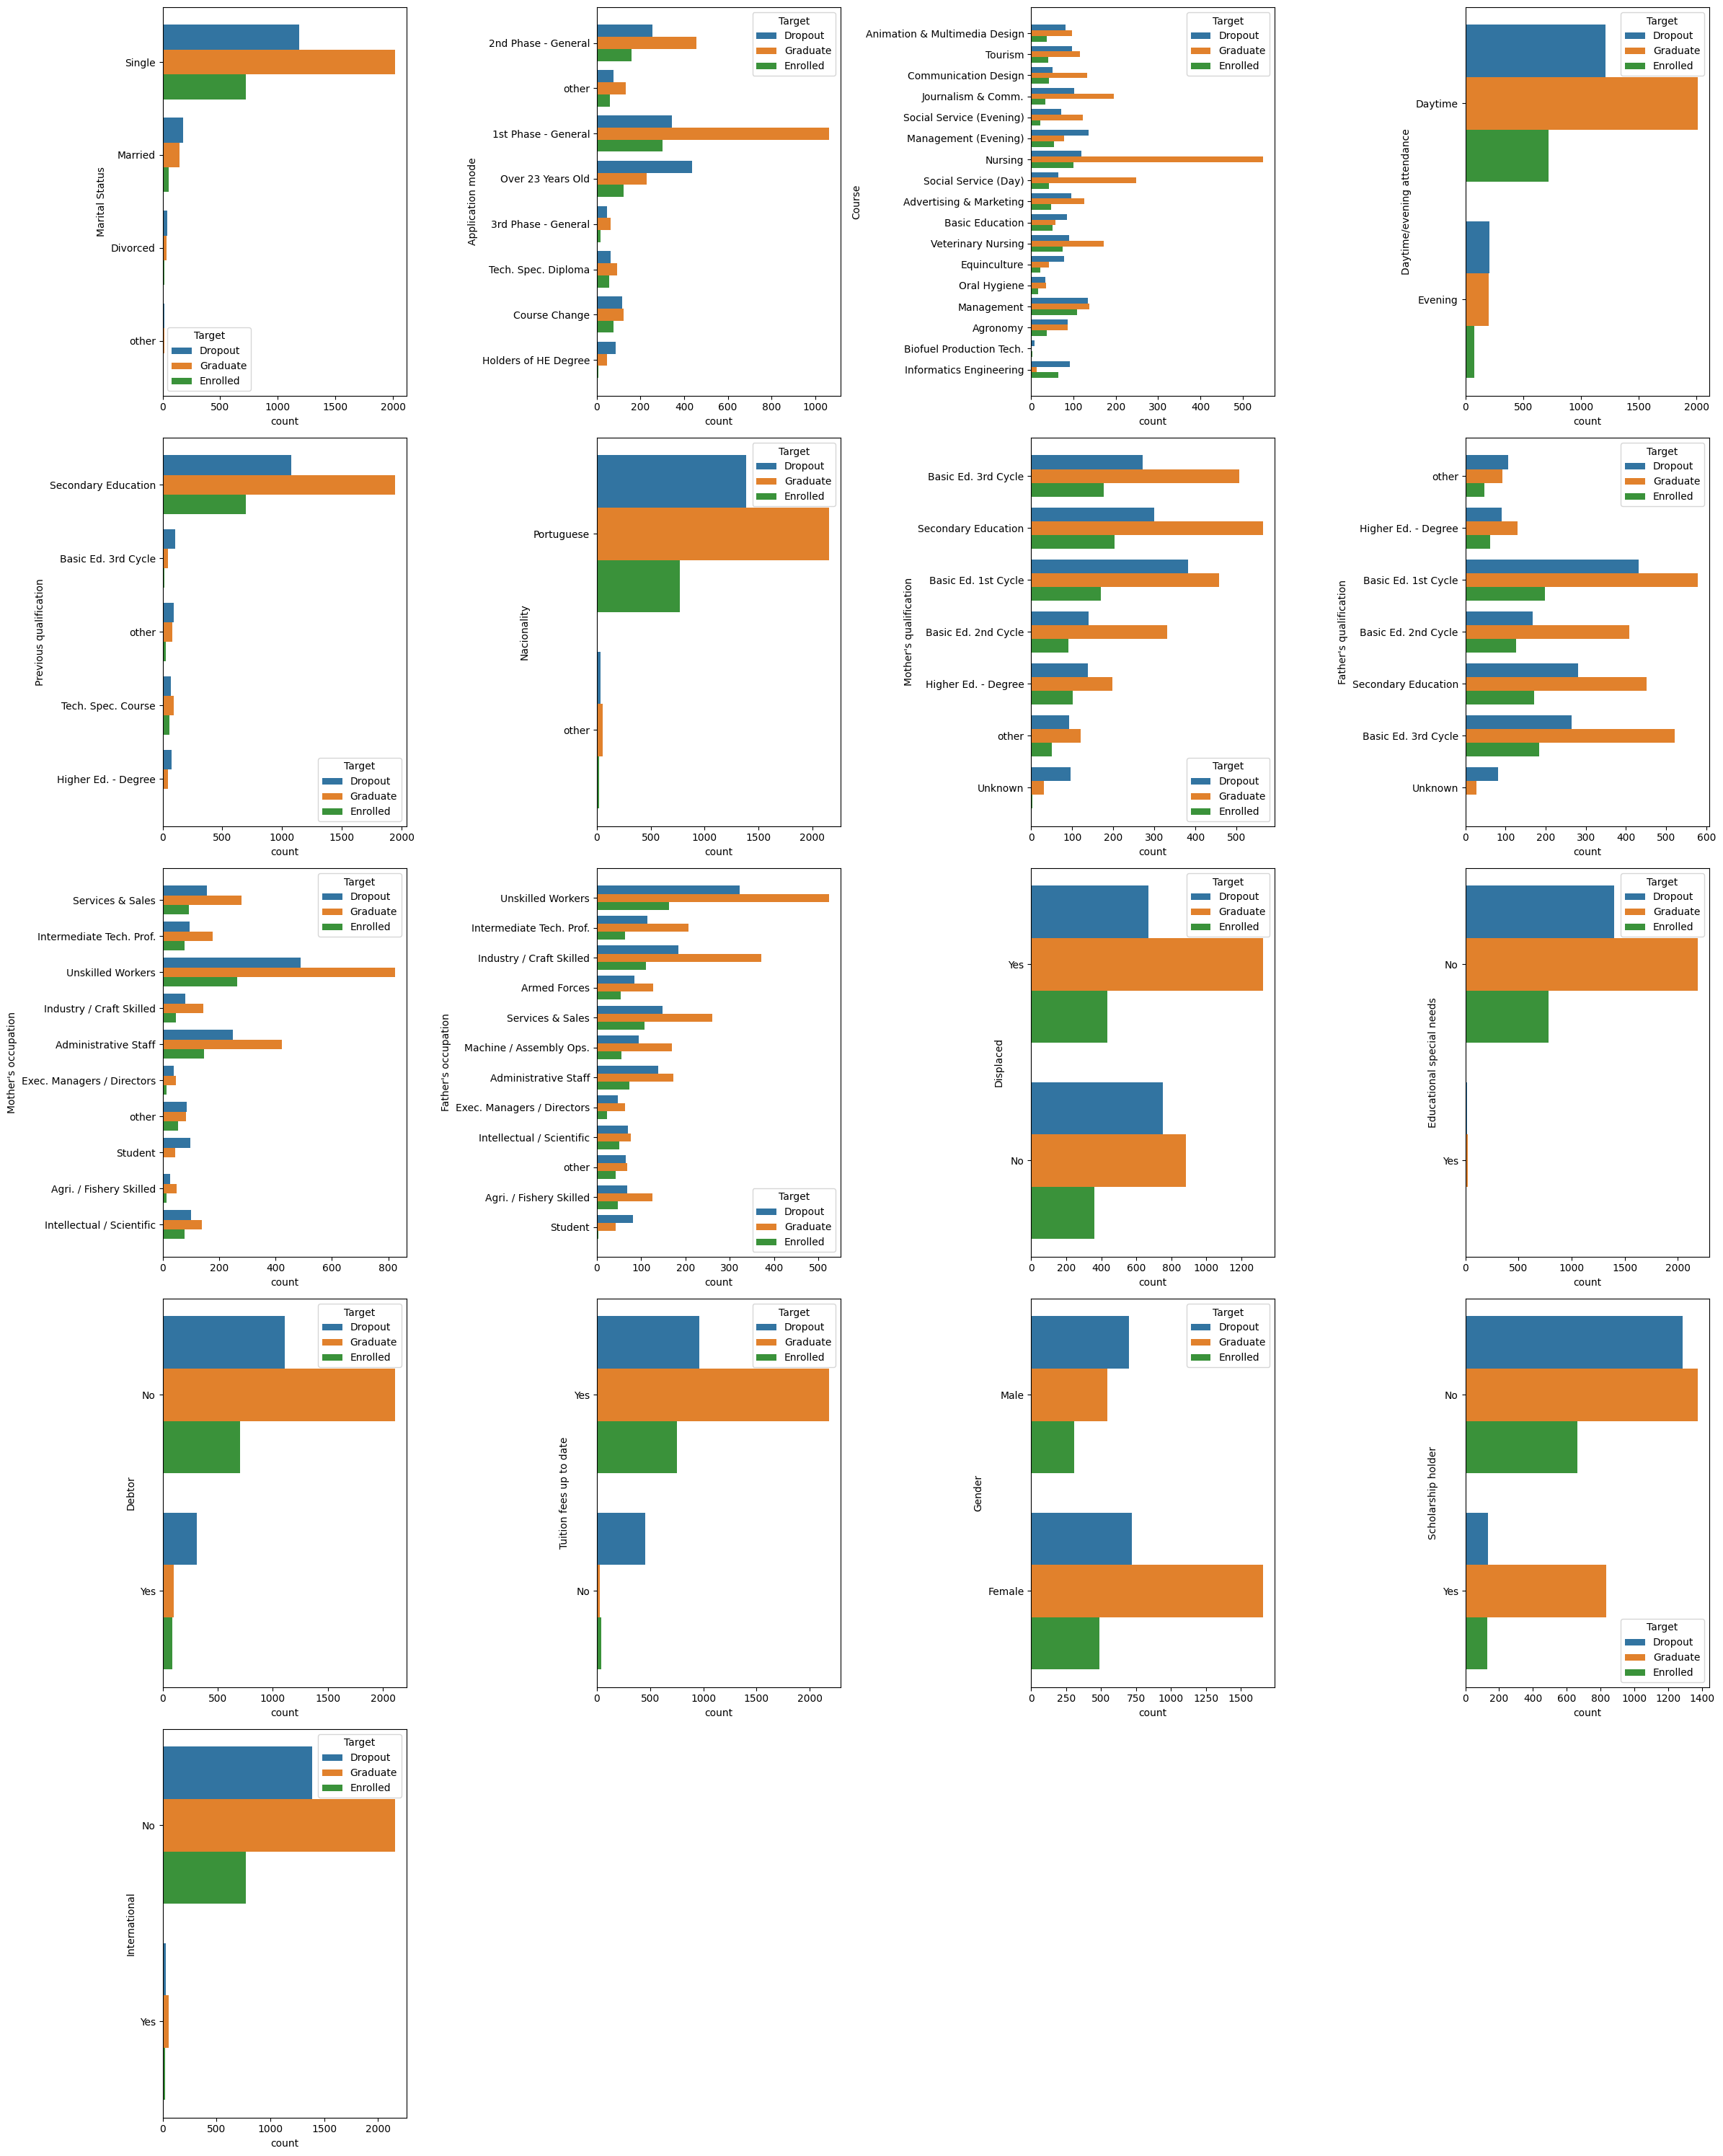

In [28]:
X , rare= other_categories(X, kategorička, 0.02)
plot_kategoricka()

In [29]:
y = y['Target'].map({'Graduate': 0, 'Dropout': 1, 'Enrolled': 2})

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [31]:
print(X.dtypes)

Marital Status                                     object
Application mode                                   object
Application order                                   int64
Course                                             object
Daytime/evening attendance                         object
Previous qualification                             object
Previous qualification (grade)                    float64
Nacionality                                        object
Mother's qualification                             object
Father's qualification                             object
Mother's occupation                                object
Father's occupation                                object
Admission grade                                   float64
Displaced                                          object
Educational special needs                          object
Debtor                                             object
Tuition fees up to date                            object
Gender        

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerička),
        ('cat', OneHotEncoder(
            sparse_output=False,
            drop='first'
        ), kategorička)
    ]
)

pipeline_knn_pca = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', BorderlineSMOTE(random_state=42)), # Added SMOTE step
    ('pca', PCA(n_components=0.90)),
    ('knn', KNeighborsClassifier())
])

param_grid_knn_pca = {
    'knn__n_neighbors': [40, 42, 44, 47, 50, 53, 57],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['cosine']
}

grid_search_knn_pca = GridSearchCV(
    pipeline_knn_pca,
    param_grid_knn_pca,
    cv=StratifiedKFold(n_splits=5),
    scoring='f1_weighted',
    error_score='raise',

 )

# Fit using X_train and y_train directly, as SMOTE is now in the pipeline
grid_search_knn_pca.fit(X_train, y_train)

# Calculate num_cols and cat_cols for printing:
temp_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerička),
        ('cat', OneHotEncoder(
            handle_unknown='infrequent_if_exist',
            min_frequency=0.02,
            sparse_output=False,
            drop='first'
        ), kategorička)
    ]
)
# Fit a temporary preprocessor to X_train to get the transformed column counts
temp_preprocessor.fit(X_train)
num_cols = len(numerička) # Number of original numerical features
cat_cols = len(temp_preprocessor.named_transformers_['cat'].get_feature_names_out()) # Number of one-hot encoded categorical features


print('Numeričkih kolona:', num_cols)
print('Kategoričkih kolona (one-hot):', cat_cols)
print('Best parameters for KNN + PCA:', grid_search_knn_pca.best_params_)
print('Best cross-validation f1 score for KNN + PCA:', grid_search_knn_pca.best_score_)

Numeričkih kolona: 10
Kategoričkih kolona (one-hot): 70
Best parameters for KNN + PCA: {'knn__metric': 'cosine', 'knn__n_neighbors': 50, 'knn__weights': 'distance'}
Best cross-validation f1 score for KNN + PCA: 0.6939770659740855


### Vizuelizacija rezultata za KNN + PCA

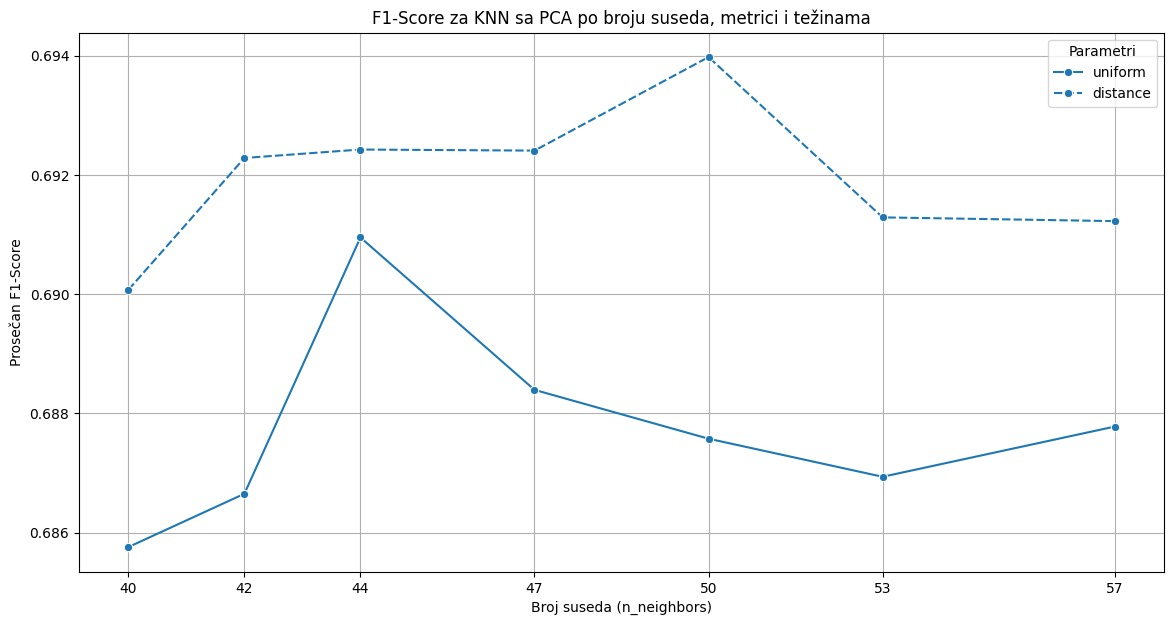

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

knn_results = pd.DataFrame(grid_search_knn_pca.cv_results_)

plt.figure(figsize=(14, 7))
sns.lineplot(
    data=knn_results,
    x='param_knn__n_neighbors',
    y='mean_test_score',
    #hue='param_knn__metric',
    style='param_knn__weights',
    marker='o'
)
plt.title('F1-Score za KNN sa PCA po broju suseda, metrici i težinama')
plt.xlabel('Broj suseda (n_neighbors)')
plt.ylabel('Prosečan F1-Score')
plt.grid(True)
plt.xticks(knn_results['param_knn__n_neighbors'].unique())
plt.legend(title='Parametri')
plt.show()

In [34]:
pipeline_mlp = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', BorderlineSMOTE(random_state=42)), # Added SMOTE step
    ('mlp', MLPClassifier(random_state=42, early_stopping=True))
])

param_grid_mlp = {
    'mlp__hidden_layer_sizes': [(65,),(68,), (70,), (72,), (75,)],
    'mlp__activation': ['relu'],
    'mlp__alpha': [0.0001,0.0005, 0.001]
}

grid_search_mlp = GridSearchCV(
    pipeline_mlp,
    param_grid_mlp,
    cv=StratifiedKFold(n_splits=5),
    scoring='f1_weighted',
    n_jobs=-1,
    error_score='raise' # Added to get more informative error
)
grid_search_mlp.fit(X_train, y_train)

print('Best parameters for MLP:', grid_search_mlp.best_params_)
print('Best cross-validation f1 score for MLP:', grid_search_mlp.best_score_)

Best parameters for MLP: {'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (72,)}
Best cross-validation f1 score for MLP: 0.7382772527108237


### Vizuelizacija rezultata za MLP

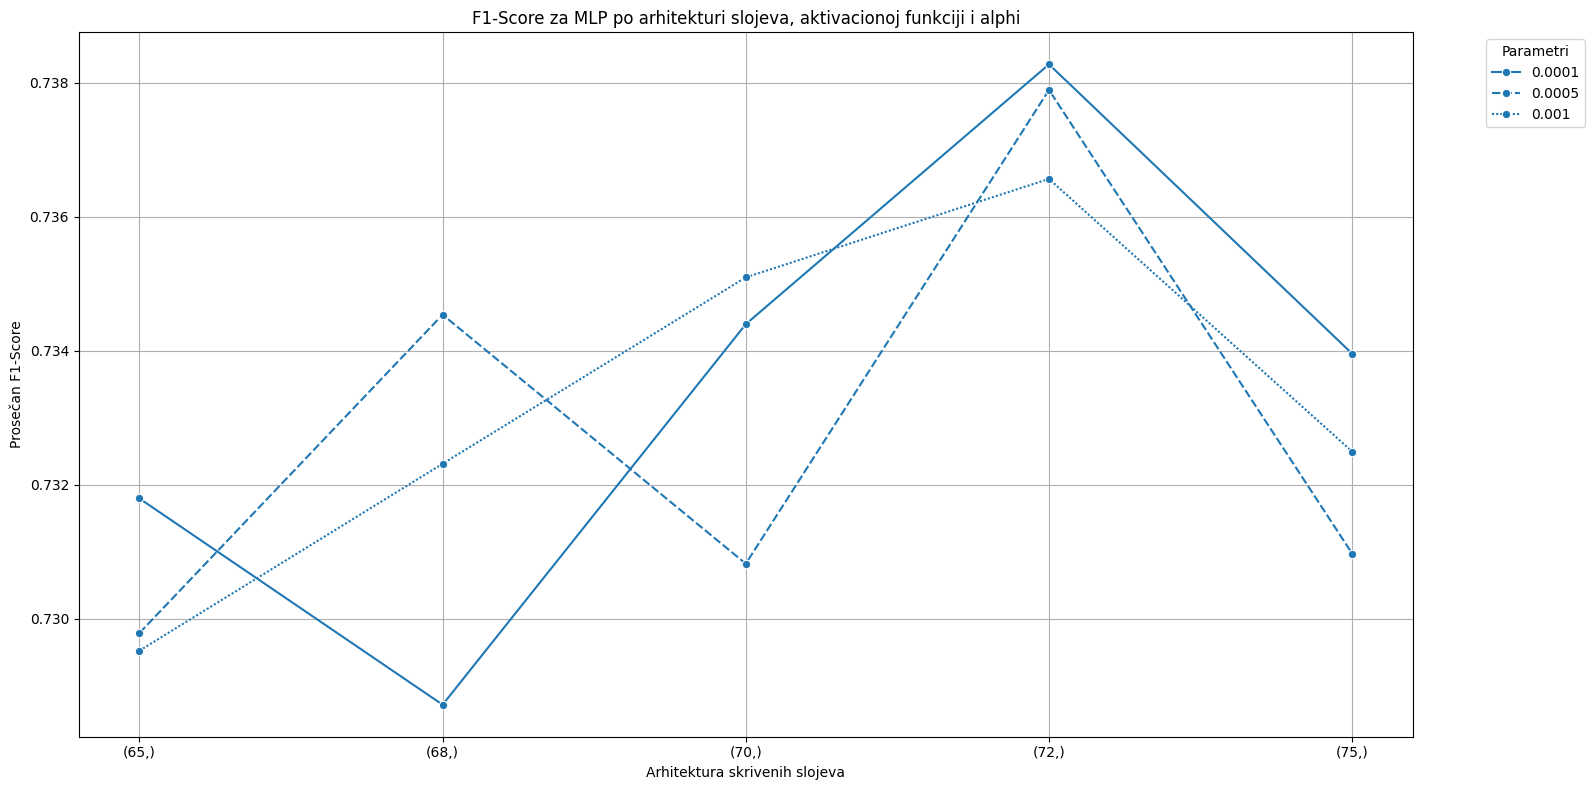

In [35]:
mlp_results = pd.DataFrame(grid_search_mlp.cv_results_)

mlp_results['param_mlp__hidden_layer_sizes_str'] = mlp_results['param_mlp__hidden_layer_sizes'].apply(str)

plt.figure(figsize=(16, 8))
sns.lineplot(
    data=mlp_results,
    x='param_mlp__hidden_layer_sizes_str',
    y='mean_test_score',
    #hue='param_mlp__activation',
    style='param_mlp__alpha',
    marker='o'
)
plt.title('F1-Score za MLP po arhitekturi slojeva, aktivacionoj funkciji i alphi')
plt.xlabel('Arhitektura skrivenih slojeva')
plt.ylabel('Prosečan F1-Score')
plt.grid(True)
plt.legend(title='Parametri', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [36]:
pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', BorderlineSMOTE(random_state=42)),
    ('lr', LogisticRegression(random_state=42, solver='liblinear', multi_class='auto', max_iter=1000))
])

param_grid_lr = {
    'lr__C': [0.01, 0.03,0.04, 0.05,0.07]
}

grid_search_lr = GridSearchCV(
    pipeline_lr,
    param_grid_lr,
    cv=StratifiedKFold(n_splits=5),
    scoring='f1_weighted',
    n_jobs=-1,
    error_score='raise'
)

grid_search_lr.fit(X_train, y_train)

print('Best parameters for Logistic Regression:', grid_search_lr.best_params_)
print('Best cross-validation f1 score for Logistic Regression:', grid_search_lr.best_score_)

Best parameters for Logistic Regression: {'lr__C': 0.03}
Best cross-validation f1 score for Logistic Regression: 0.7441811867337143


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### Vizuelizacija rezultata za Logističku regresiju

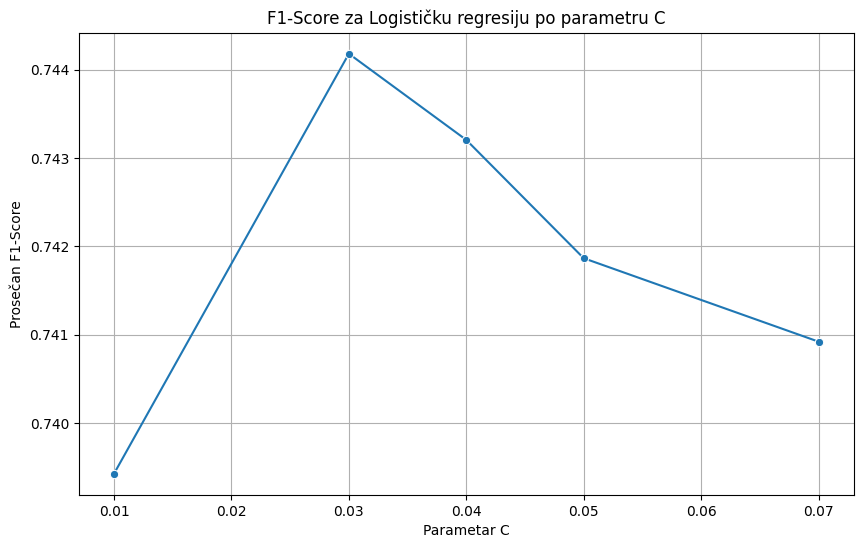

In [37]:
lr_results = pd.DataFrame(grid_search_lr.cv_results_)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=lr_results,
    x='param_lr__C',
    y='mean_test_score',
    marker='o'
)
plt.title('F1-Score za Logističku regresiju po parametru C')
plt.xlabel('Parametar C')
plt.ylabel('Prosečan F1-Score')
#plt.xscale('log')
plt.grid(True, which='both')
plt.show()

### Evaluacija KNN + PCA modela na test skupu

In [38]:
best_knn_pca_model = grid_search_knn_pca.best_estimator_
y_pred_knn_pca = best_knn_pca_model.predict(X_test)

print('KNN + PCA Test F1-Score (weighted):', f1_score(y_test, y_pred_knn_pca, average='weighted'))
print('\nClassification Report for KNN + PCA:')
print(classification_report(y_test, y_pred_knn_pca))

KNN + PCA Test F1-Score (weighted): 0.6660917901700679

Classification Report for KNN + PCA:
              precision    recall  f1-score   support

           0       0.82      0.67      0.74       442
           1       0.74      0.70      0.72       284
           2       0.31      0.48      0.38       159

    accuracy                           0.65       885
   macro avg       0.62      0.62      0.61       885
weighted avg       0.70      0.65      0.67       885



### Evaluacija MLP modela na test skupu

In [39]:
best_mlp_model = grid_search_mlp.best_estimator_
y_pred_mlp = best_mlp_model.predict(X_test)

print('MLP Test F1-Score (weighted):', f1_score(y_test, y_pred_mlp, average='weighted'))
print('\nClassification Report for MLP:')
print(classification_report(y_test, y_pred_mlp))



MLP Test F1-Score (weighted): 0.7207666163142223

Classification Report for MLP:
              precision    recall  f1-score   support

           0       0.84      0.79      0.81       442
           1       0.76      0.77      0.76       284
           2       0.36      0.41      0.38       159

    accuracy                           0.72       885
   macro avg       0.65      0.66      0.65       885
weighted avg       0.73      0.72      0.72       885



### Evaluacija Logističke regresije na test skupu

In [40]:
best_lr_model = grid_search_lr.best_estimator_
y_pred_lr = best_lr_model.predict(X_test)

print('Logistic Regression Test F1-Score (weighted):', f1_score(y_test, y_pred_lr, average='weighted'))
print('\nClassification Report for Logistic Regression:')
print(classification_report(y_test, y_pred_lr))


Logistic Regression Test F1-Score (weighted): 0.7176519765538248

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.83      0.78      0.81       442
           1       0.76      0.77      0.77       284
           2       0.36      0.42      0.39       159

    accuracy                           0.71       885
   macro avg       0.65      0.66      0.65       885
weighted avg       0.73      0.71      0.72       885



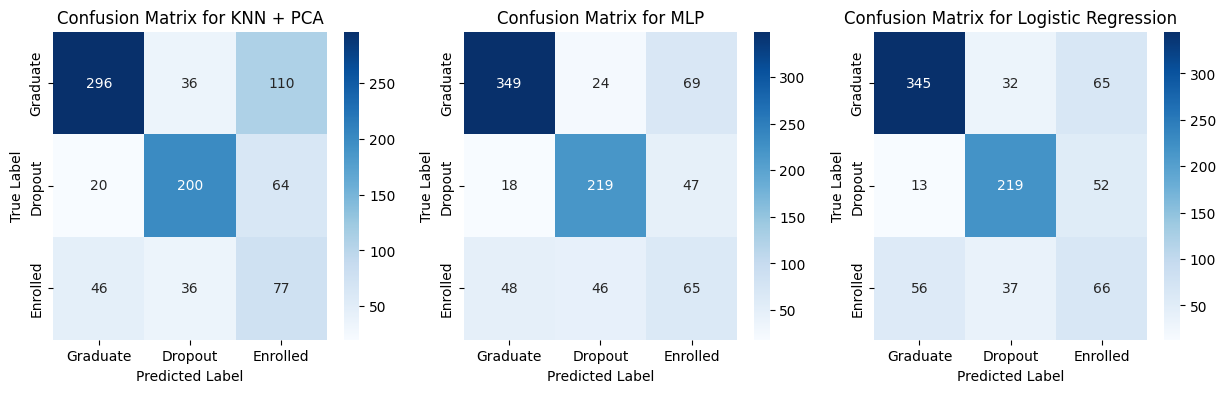

In [41]:
plt.figure(figsize=(15,4))
plt.subplot(131)

sns.heatmap(confusion_matrix(y_test, y_pred_knn_pca), annot=True, fmt='d', cmap='Blues', xticklabels=['Graduate', 'Dropout', 'Enrolled'], yticklabels=['Graduate', 'Dropout', 'Enrolled'])
plt.title('Confusion Matrix for KNN + PCA')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.subplot(132)

sns.heatmap(confusion_matrix(y_test, y_pred_mlp), annot=True, fmt='d', cmap='Blues', xticklabels=['Graduate', 'Dropout', 'Enrolled'], yticklabels=['Graduate', 'Dropout', 'Enrolled'])
plt.title('Confusion Matrix for MLP')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.subplot(133)

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', xticklabels=['Graduate', 'Dropout', 'Enrolled'], yticklabels=['Graduate', 'Dropout', 'Enrolled'])
plt.title('Confusion Matrix for Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.autoscale()
plt.show()

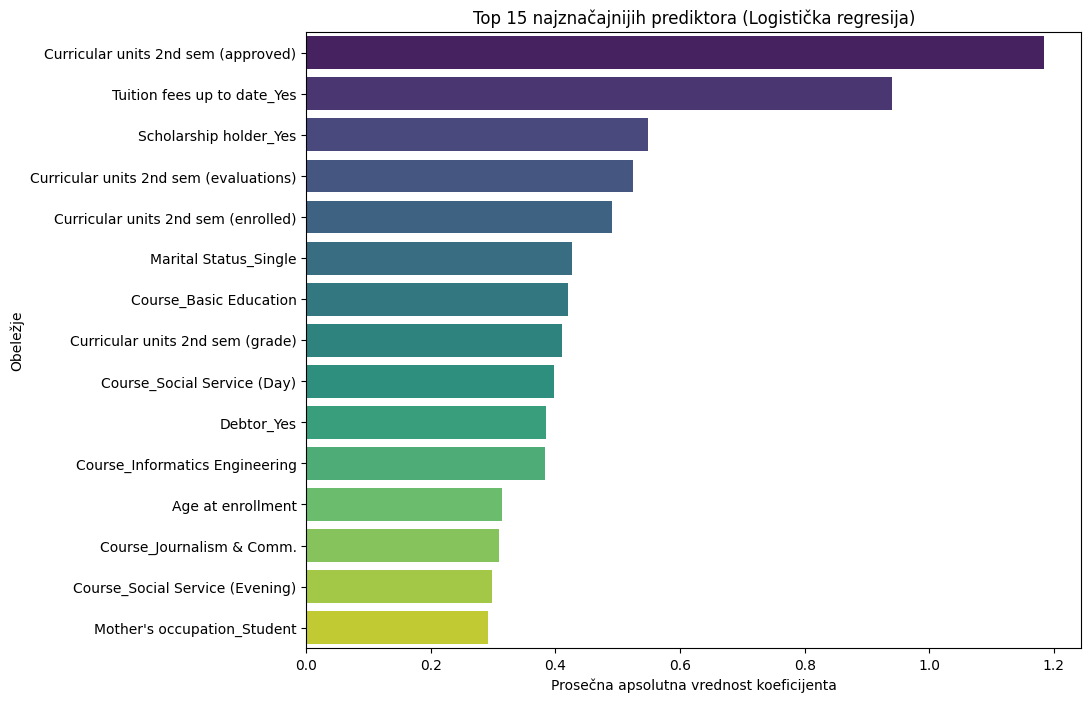

In [42]:
cat_encoder = grid_search_lr.best_estimator_.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_names = list(cat_encoder.get_feature_names_out(kategorička))
feature_names = list(numerička) + encoded_cat_names

coefs = grid_search_lr.best_estimator_.named_steps['lr'].coef_
importance = np.mean(np.abs(coefs), axis=0)

feature_importance = pd.DataFrame({'Obeležje': feature_names, 'Važnost': importance})
feature_importance = feature_importance.sort_values(by='Važnost', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Važnost', y='Obeležje', data=feature_importance.head(15), hue='Obeležje', palette='viridis', legend=False)
plt.title('Top 15 najznačajnijih prediktora (Logistička regresija)')
plt.xlabel('Prosečna apsolutna vrednost koeficijenta')
plt.show()